# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Автор Поладов Селим Бегенджович. Вариант NLP, русский язык. Основная модель ruBERT-tiny2, лицензия MIT. Русскую часть WikiNEuRal беру из официальных сплитов, лицензия CC BY-NC-SA 4.0. Выбраны бонусы 6.2, 6.3, 6.4 и 6.5. Финальный прогон выполнен в Google Colab на Tesla T4. Задержку после квантизации измеряю на CPU этой же машины.

Источники. [Карточка ruBERT-tiny2](https://huggingface.co/cointegrated/rubert-tiny2), [карточка ruBERT-tiny](https://huggingface.co/cointegrated/rubert-tiny), [сравнение энкодеров автором](https://habr.com/ru/articles/669674/), [данные и лицензия WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural), [описание разметки](https://aclanthology.org/2021.findings-emnlp.215/). Для обучения использованы [Transformers Trainer](https://huggingface.co/docs/transformers/main_classes/trainer) и функции шаблона. Для оценки сущностей использован [seqeval](https://github.com/chakki-works/seqeval).

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'   # ваш код: id модели на Hugging Face Hub
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'   # ваш код: полный commit hash (40 символов)
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Выбрал ruBERT-tiny2 для русских текстов. У него три слоя, около 29 млн параметров и словарь на 83 828 токенов. Авторы продолжили обучение маленького BERT на предсказании пропущенных токенов, логическом выводе и приближении векторов LaBSE. Обе версии tiny опубликованы под MIT. У первой версии около 12 млн параметров и словарь на 29 564 токена для русского и английского. В сравнении автора на factRuEval при замороженных представлениях оценка составила 0.40 у tiny2 и 0.23 у tiny. У многоязычного BERT из списка задания она составила 0.35, а обработка на GPU в том же бенчмарке заняла примерно втрое больше времени, чем у tiny2. Для нашей задачи проверю качество после дообучения отдельно. Фиксирую ревизию, чтобы веса, словарь и настройки токенизации при следующем запуске взялись из одной и той же версии. [Сравнение автора](https://habr.com/ru/articles/669674/)

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    base = model.base_model
    layers = base.encoder.layer
    def count(module):
        return sum(p.numel() for p in module.parameters())

    per_layer = [count(layer) for layer in layers]
    embeddings = count(base.embeddings)
    head = count(model.classifier)
    return dict(embeddings=embeddings, encoder=sum(per_layer), head=head,
                other=count(model) - embeddings - sum(per_layer) - head, layers=per_layer)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)
for name in ('input_ids', 'attention_mask'):
    print(name, tuple(enc[name].shape))
print('hidden states', [tuple(h.shape) for h in out.hidden_states])
print('logits', tuple(out.logits.shape))

input_ids (2, 11)
attention_mask (2, 11)
hidden states [(2, 11, 312), (2, 11, 312), (2, 11, 312), (2, 11, 312)]
logits (2, 11, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 5.5 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Для двух предложений токенизатор вернул матрицы индексов и маски размером 2 на 11. Часть слов разбилась на несколько токенов, добавились служебные токены и выравнивание по длине. Эмбеддинги и выходы трёх слоёв имеют размер 2 на 11 на 312. Между позициями информация передаётся в attention, а полносвязная часть каждого слоя и классификатор применяются к каждой позиции отдельно. В эмбеддингах 26 794 560 параметров из 29 098 303, около 92.1 процента. Основная часть приходится на отдельный вектор для каждого элемента словаря. Демонстрационная голова выдаёт семь оценок на позицию, поэтому форма logits равна 2 на 11 на 7.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID = 'Babelscape/wikineural'
DATASET_CONFIG = None
DATA_REVISION = '74c9b9dca034bb1606a6769457983904bd976803'
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
split_files = {'train': 'train_ru', 'validation': 'val_ru', 'test': 'test_ru'}
files = {split: f'hf://datasets/{DATASET_ID}@{DATA_REVISION}/data/{name}-00000-of-00001.parquet'
         for split, name in split_files.items()}
corpus = load_dataset('parquet', data_files=files)
limits = {'train': 12000, 'validation': 2000, 'test': 2000}
raw = DatasetDict({s: ds.shuffle(seed=SEED).select(range(min(len(ds), limits[s])))
                   for s, ds in corpus.items()})
print('исходные сплиты', {s: len(ds) for s, ds in corpus.items()})
print('выборка', {s: len(ds) for s, ds in raw.items()})

исходные сплиты {'train': 92320, 'validation': 11540, 'test': 11580}
выборка {'train': 12000, 'validation': 2000, 'test': 2000}


In [14]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
for split, ds in raw.items():
    types = collections.Counter()
    span_lengths, lengths = [], []
    for ex in ds:
        tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
        assert len(tags) == len(ex['tokens'])
        lengths.append(len(tags))
        previous = None
        for tag in tags:
            entity = tag[2:] if tag != 'O' else None
            if entity is not None:
                if tag.startswith('B-') or entity != previous:
                    types[entity] += 1
                    span_lengths.append(1)
                else:
                    span_lengths[-1] += 1
            previous = entity
    print(split, 'сущности', dict(sorted(types.items())))
    for name, values in [('предложение', lengths), ('сущность', span_lengths)]:
        print(name, 'среднее', round(float(np.mean(values)), 2),
              'медиана, p90, максимум', np.percentile(values, [50, 90, 100]).tolist())

train сущности {'LOC': 8915, 'MISC': 3155, 'ORG': 2614, 'PER': 4300}
предложение среднее 19.56 медиана, p90, максимум [17.0, 33.100000000000364, 135.0]
сущность среднее 1.3 медиана, p90, максимум [1.0, 2.0, 17.0]
validation сущности {'LOC': 1525, 'MISC': 461, 'ORG': 464, 'PER': 741}
предложение среднее 18.75 медиана, p90, максимум [17.0, 32.0, 107.0]
сущность среднее 1.32 медиана, p90, максимум [1.0, 2.0, 8.0]


test сущности {'LOC': 1566, 'MISC': 490, 'ORG': 526, 'PER': 635}
предложение среднее 18.77 медиана, p90, максимум [17.0, 32.0, 90.0]
сущность среднее 1.35 медиана, p90, максимум [1.0, 2.0, 11.0]


**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** WikiNEuRal построен по Википедии. Авторы автоматически разметили тексты с помощью BabelNet и нейросетей, лицензия CC BY-NC-SA 4.0. В опубликованных русских сплитах 92 320, 11 540 и 11 580 предложений. Для трёх сопоставимых обучений взял случайные 12 000 из train и по 2 000 из validation и test с seed 0. В обучающей выборке 8 915 упоминаний LOC, 4 300 PER, 3 155 MISC и 2 614 ORG. Медианная длина сущности одно слово, предложения 17 слов. У редких организаций меньше обучающих примеров, а для длинного названия ошибка на одном крайнем слове уже портит совпадение всей сущности. [WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural)

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans = []
    for i, tag in enumerate(tags):
        if tag == 'O':
            continue
        prefix, kind = tag.split('-', 1)
        if prefix == 'I' and spans and spans[-1][1:] == (i, kind):
            spans[-1] = (spans[-1][0], i + 1, kind)
        else:
            spans.append((i, i + 1, kind))
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, kind in spans:
        if not 0 <= start < end <= n_words or any(t != 'O' for t in tags[start:end]):
            raise ValueError('Некорректные границы сущности')
        tags[start:end] = ['B-' + kind] + ['I-' + kind] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels = []
    previous = None
    for word in word_ids:
        if word is None:
            labels.append(-100)
        elif word != previous:
            labels.append(word_labels[word])
        elif b_to_i is None:
            labels.append(-100)
        else:
            labels.append(b_to_i.get(word_labels[word], word_labels[word]))
        previous = word
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
Path('data').mkdir(exist_ok=True)
for split, ds in raw.items():
    path = Path('data') / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as stream:
        for ex in ds:
            spans = bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
            stream.write(json.dumps(dict(tokens=ex['tokens'], spans=spans), ensure_ascii=False) + '\n')
    changed = 0
    with path.open(encoding='utf-8') as stream:
        for ex, line in zip(ds, stream, strict=True):
            record = json.loads(line)
            assert record['tokens'] == ex['tokens']
            tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
            restored = spans_to_bio(record['spans'], len(tags))
            assert bio_to_spans(restored) == bio_to_spans(tags)
            changed += restored != tags
    print(split, 'проверено', len(ds), 'исправлен BIO', changed)

train проверено 12000 исправлен BIO 414


validation проверено 2000 исправлен BIO 60


test проверено 2000 исправлен BIO 76


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 12000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 2000
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']


train: проверено 11990 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 178
[CLS]            None  -100
Работы              0  O
по                  1  O
строительству       2  O
первоначальной      3  O
инфраструктуры      4  O
аэропорта           5  O
начались            6  O
в                   7  O
1937                8  O
году                9  O
на                 10  O
месте              11  O
девяти             12  O
сельскохозяйственных   13  O
угодий             14  O
,                  15  O
выкуп              16  O
##ленных           16  -100
муниципальным      17  O
комитетом          18  O
Торонто            19  B-LOC
у                  20  O
частных            21  O
владельцев         22  O
.                  23  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** У слова одна метка, поэтому считаю loss только по первому сабворду. Индекс −100 исключает остальные позиции из cross entropy, и длинные слова не получают лишний вес. При чтении JSONL обратно границы и типы совпали во всех 16 000 предложениях. В train у 414 предложений изменилась запись BIO, поскольку изолированный I начинал сущность и при восстановлении стал B. Из 12 000 обучающих предложений 10 длиннее лимита в 128 токенов. За границей осталось 178 целых слов. При токенизации без обрезки каждое слово получило хотя бы один сабворд. В оценке шаблон присваивает невидимым словам тег O, поэтому может пропустить или укоротить сущность.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list, strict=True):
        for word, tag in zip(words, tags, strict=True):
            counts[word][tag] += 1
    return {word: counter.most_common(1)[0][0] for word, counter in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
tagger = fit_majority_tagger(data['train']['tokens'], train_tags)
majority = [predict_majority(tagger, words) for words in val_tokens]
set_seed(SEED)
untrained = make_model()
random_pred = predict_word_tags(untrained, val_tokens)
baseline = {'majority': entity_scores(val_gold, majority),
            'random_head': entity_scores(val_gold, random_pred)}
print('validation', baseline)
del untrained

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

validation {'majority': {'f1_micro': np.float64(0.44642503466032885), 'f1_macro': np.float64(0.3841321520619849), 'precision': np.float64(0.6065662002152853), 'recall': np.float64(0.3531808210592291)}, 'random_head': {'f1_micro': np.float64(0.029435132987779496), 'f1_macro': np.float64(0.027572158544311078), 'precision': np.float64(0.01673838209982788), 'recall': np.float64(0.12190535882168599)}}


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** На validation словарный бейзлайн дал F1 0.4464 при precision 0.6066 и recall 0.3532. Повторяющиеся написания имён помогают, но другая падежная форма для словаря уже отдельное слово. Он также не различает значения одного слова в разных контекстах. Энкодер со случайной головой дал F1 0.0294 и precision 0.0167. Он уже строит контекстные представления, но случайные веса классификатора ещё не связывают их с девятью нашими тегами.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    model.base_model.requires_grad_(not freeze_encoder)
    steps_per_epoch = math.ceil(len(train_ds) / batch_size)
    interval = max(1, steps_per_epoch * epochs // 10)
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=batch_size * 2,
        warmup_steps=max(1, round(0.1 * steps_per_epoch * epochs)), weight_decay=0.01,
        lr_scheduler_type='linear', fp16=device.type == 'cuda', seed=SEED,
        data_seed=SEED, logging_steps=interval, eval_strategy='steps', eval_steps=interval,
        save_strategy='no', report_to='none', disable_tqdm=True, dataloader_num_workers=0)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      processing_class=tok, data_collator=DataCollatorForTokenClassification(tok))
    start = time.perf_counter()
    trainer.train()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    return trainer.state.log_history, time.perf_counter() - start

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.6605', 'grad_norm': '0.9719', 'learning_rate': '0.0001982', 'epoch': '0.2987'}


{'eval_loss': '0.1816', 'eval_runtime': '0.4889', 'eval_samples_per_second': '4090', 'eval_steps_per_second': '65.45', 'epoch': '0.2987'}


{'loss': '0.1392', 'grad_norm': '0.8108', 'learning_rate': '0.0001781', 'epoch': '0.5973'}


{'eval_loss': '0.1086', 'eval_runtime': '0.6599', 'eval_samples_per_second': '3031', 'eval_steps_per_second': '48.49', 'epoch': '0.5973'}


{'loss': '0.103', 'grad_norm': '0.6522', 'learning_rate': '0.000156', 'epoch': '0.896'}


... (12 outputs left out)

{'eval_loss': '0.08411', 'eval_runtime': '0.4684', 'eval_samples_per_second': '4270', 'eval_steps_per_second': '68.32', 'epoch': '2.688'}


{'loss': '0.03154', 'grad_norm': '1.695', 'learning_rate': '1.185e-06', 'epoch': '2.987'}


{'eval_loss': '0.08381', 'eval_runtime': '0.4822', 'eval_samples_per_second': '4148', 'eval_steps_per_second': '66.36', 'epoch': '2.987'}


{'eval_loss': '0.08381', 'eval_runtime': '0.4611', 'eval_samples_per_second': '4338', 'eval_steps_per_second': '69.41', 'epoch': '3'}
{'train_runtime': '36.16', 'train_samples_per_second': '995.7', 'train_steps_per_second': '31.12', 'train_loss': '0.1244', 'epoch': '3'}
обучение: 36.4 c на Tesla T4, 12000 предложений, 3 эпох(а)


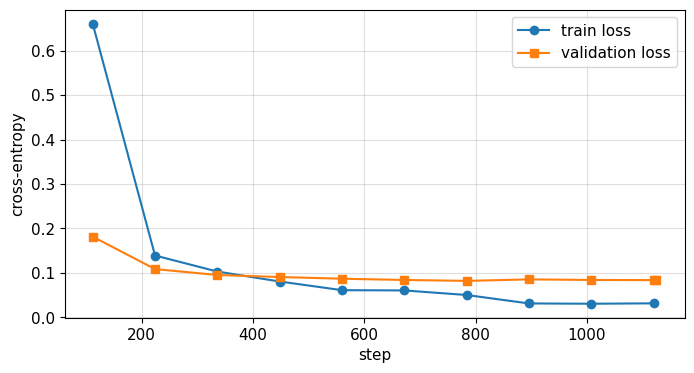

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Взял шаг $2\cdot10^{-4}$ для маленького энкодера, батч 32 и три эпохи. Первые 10 процентов шагов отвёл на разогрев, затем линейно уменьшал шаг. Weight decay 0.01 ограничивает рост весов, а fp16 экономит память GPU. На Tesla T4 обучение с проверками заняло 36.4 с. Train loss снизился с 0.6605 до 0.0315. Validation loss сначала упал с 0.1816 до 0.0820 около эпохи 2.1, а в конце составил 0.0838. После второй эпохи выигрыш остановился, поэтому по этой кривой добавлять эпохи оснований нет.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    right = positive = predicted = 0
    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for g, p in zip(gold_tags, pred_tags, strict=True):
            positive += g != 'O'
            predicted += p != 'O'
            right += g == p and g != 'O'
    return 2 * right / (positive + predicted) if positive + predicted else 0.0

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

def report(gold, pred):
    scores = entity_scores(gold, pred)
    rows = classification_report(gold, pred, output_dict=True, zero_division=0)
    scores['token_f1'] = token_f1(gold, pred)
    scores['per_type'] = {name: rows[name] for name in ENTITY_TYPES if name in rows}
    return scores

test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
val_pred, val_probs = predict_word_tags(model, val_tokens, return_probs=True)
validation = report(val_gold, val_pred)
final = report(test_gold, predict_word_tags(model, test_tokens))
print('validation', validation)
print('test', final)

validation {'f1_micro': np.float64(0.8133764832793959), 'f1_macro': np.float64(0.7683624443294039), 'precision': np.float64(0.8001819284414797), 'recall': np.float64(0.8270134753995613), 'token_f1': 0.8332541567695962, 'per_type': {'LOC': {'precision': np.float64(0.8767650834403081), 'recall': np.float64(0.8957377049180328), 'f1-score': np.float64(0.8861498540382744), 'support': np.int64(1525)}, 'MISC': {'precision': np.float64(0.6450939457202505), 'recall': np.float64(0.6702819956616052), 'f1-score': np.float64(0.6574468085106383), 'support': np.int64(461)}, 'ORG': {'precision': np.float64(0.68125), 'recall': np.float64(0.7047413793103449), 'f1-score': np.float64(0.6927966101694916), 'support': np.int64(464)}, 'PER': {'precision': np.float64(0.8156209987195903), 'recall': np.float64(0.8596491228070176), 'f1-score': np.float64(0.8370565045992117), 'support': np.int64(741)}}}
test {'f1_micro': np.float64(0.8088726830750531), 'f1_macro': np.float64(0.764813632199049), 'precision': np.flo

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** На test хуже всего MISC с F1 0.6580 по 490 сущностям. Это разнородный класс с меньшим числом примеров, чем у LOC, где F1 достиг 0.8913 по 1 566 сущностям. Micro F1 равен 0.8089, потому что частые географические названия сильнее влияют на общие счётчики. В macro F1 каждый тип имеет одинаковый вес, поэтому он ниже, 0.7648. F1 по словам равен 0.8310. Если модель нашла часть длинного названия, правильные слова получат зачёт, а сущность целиком будет ошибкой. Для извлечения имён из документа нужен именно F1 по целым сущностям.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    result = []
    matched = set()
    for g in gold_spans:
        overlaps = [p for p in pred_spans if p[0] < g[1] and g[0] < p[1]]
        matched.update(overlaps)
        if not overlaps:
            result.append(('missed', g, None))
            continue
        same = [p for p in overlaps if p[2] == g[2]]
        if g in same:
            result.append(('correct', g, g))
        else:
            best = max(same or overlaps, key=lambda p: min(p[1], g[1]) - max(p[0], g[0]))
            result.append(('boundary' if same else 'type', g, best))
    return result + [('spurious', None, p) for p in pred_spans if p not in matched]

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

counts = collections.Counter()
examples = collections.defaultdict(list)
for words, gold_tags, predicted in zip(val_tokens, val_gold, val_pred):
    for kind, gold_span, pred_span in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(predicted)):
        counts[kind] += 1
        if kind != 'correct' and len(examples[kind]) < 2:
            examples[kind].append((' '.join(words), gold_span, pred_span))
errors = {kind: counts[kind] for kind in ERROR_CATEGORIES}
n_errors = sum(errors.values()) - errors['correct']
print('категории', errors)
for kind, cases in examples.items():
    print(kind, 'доля ошибок', round(counts[kind] / n_errors, 3))
    for sentence, gold_span, pred_span in cases:
        print(sentence, '\nразметка', gold_span, 'прогноз', pred_span)

категории {'correct': 2639, 'boundary': 167, 'type': 311, 'missed': 74, 'spurious': 132}
boundary доля ошибок 0.244
Брокхауз стал профессором в университете Мак-Мастера в Канаде , где и оставался до пенсии в 1984 г . 
разметка (4, 6, 'LOC') прогноз (5, 6, 'LOC')
23 декабря 2007 года подписал двухлетний контракт с новосибирской « Сибирью » , осуществив мечту играть за родной город . 
разметка (10, 12, 'ORG') прогноз (9, 12, 'ORG')
spurious доля ошибок 0.193
Сведения , данные апостолами Лукой и Иоанном , носят относительно противоречивый характер . 
разметка None прогноз (3, 4, 'PER')
В марте 1922 года в Чурапче они учредили Временное якутское областное народное управление . 
разметка None прогноз (8, 13, 'ORG')
type доля ошибок 0.455
Согласно предъявленному в дальнейшем обвинению в пиратстве , первое разбойное нападение Кидда было совершено недалеко от Тулеара , на юго-западе Мадагаскара в конце 1696 года , куда на самом деле « Приключение » после долгого путешествия вдоль западного поб

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** На validation чаще всего путается тип, 311 из 684 ошибок, или 45.5 процента. Например, фамилию Кидда модель приняла за место. При ошибке границ она нашла Мак-Мастера, но оставила за спаном слово университете. Среди пропусков есть название компании CD Projekt, а среди лишних предсказаний есть нарицательное слово апостолами с тегом PER. Есть и спорный случай в самой разметке. Во фразе об учреждении Временного якутского областного народного управления модель выделила название учреждения как ORG, а в эталоне его нет. Это кандидат на ручную проверку. Сначала я бы проверил спорные метки на обучающей выборке и добавил проверенные контексты с похожими названиями людей, мест и организаций.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
set_seed(SEED)
frozen = make_model()
_, frozen_seconds = train_ner(frozen, tokenized['train'], tokenized['validation'],
                              freeze_encoder=True, out_dir='runs/frozen')
frozen_scores = entity_scores(val_gold, predict_word_tags(frozen, val_tokens))
def trainable(net):
    return sum(p.numel() for p in net.parameters() if p.requires_grad)

ablation = {'setting': ABLATION,
            'full': dict(f1=validation['f1_micro'], seconds=train_seconds, trainable=trainable(model)),
            'frozen': dict(f1=frozen_scores['f1_micro'], seconds=frozen_seconds, trainable=trainable(frozen))}
print(ablation)
del frozen

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.7', 'grad_norm': '2.968', 'learning_rate': '0.0001982', 'epoch': '0.2987'}


{'eval_loss': '0.9918', 'eval_runtime': '0.4663', 'eval_samples_per_second': '4289', 'eval_steps_per_second': '68.62', 'epoch': '0.2987'}


{'loss': '0.5875', 'grad_norm': '0.4597', 'learning_rate': '0.0001781', 'epoch': '0.5973'}


{'eval_loss': '0.4171', 'eval_runtime': '0.4819', 'eval_samples_per_second': '4150', 'eval_steps_per_second': '66.41', 'epoch': '0.5973'}


{'loss': '0.3695', 'grad_norm': '0.4024', 'learning_rate': '0.000156', 'epoch': '0.896'}


... (13 outputs left out)

{'loss': '0.2612', 'grad_norm': '0.2506', 'learning_rate': '1.185e-06', 'epoch': '2.987'}


{'eval_loss': '0.2473', 'eval_runtime': '0.4861', 'eval_samples_per_second': '4114', 'eval_steps_per_second': '65.83', 'epoch': '2.987'}


{'eval_loss': '0.2473', 'eval_runtime': '0.4779', 'eval_samples_per_second': '4185', 'eval_steps_per_second': '66.95', 'epoch': '3'}
{'train_runtime': '21.26', 'train_samples_per_second': '1693', 'train_steps_per_second': '52.91', 'train_loss': '0.4609', 'epoch': '3'}


{'setting': 'freeze', 'full': {'f1': np.float64(0.8133764832793959), 'seconds': 36.44428503099999, 'trainable': 29098929}, 'frozen': {'f1': np.float64(0.50278940027894), 'seconds': 21.582081088000052, 'trainable': 2817}}


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** При одинаковых сплитах, начальных весах и трёх эпохах заморозка оставила 2 817 обучаемых параметров вместо 29 098 929. Обучение сократилось с 36.4 до 21.6 с, но F1 на validation упал с 0.8134 до 0.5028. Одной линейной голове трудно одновременно восстановить границы и различить типы по неизменным представлениям. Для проверки устойчивости разницы повторил бы оба варианта на нескольких seed.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** На validation полный ruBERT-tiny2 поднял F1 с 0.4464 у словаря до 0.8134. С замороженным энкодером получилось 0.5028, поэтому основную прибавку в этом опыте дало дообучение представлений. На отложенном тесте F1 по целым сущностям равен 0.8089, по отдельным словам 0.8310. Самый сильный тип на тесте LOC с F1 0.8913, самый слабый MISC с 0.6580. Разбор показал, что часть расхождений может идти от автоматической разметки, особенно у названий организаций. Опыт проведён с одним seed на подвыборке Википедии. Дальше проверил бы ту же модель на вручную размеченных новостях и отдельно сравнил ошибки типов и границ.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "Babelscape/wikineural", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 12000, "n_val": 2000, "n_test": 2000, "params_total": 29098929, "ablation": {"setting": "freeze", "full": {"f1": 0.8133764832793959, "seconds": 36.44428503099999, "trainable": 29098929}, "frozen": {"f1": 0.50278940027894, "seconds": 21.582081088000052, "trainable": 2817}}, "errors": {"correct": 2639, "boundary": 167, "type": 311, "missed": 74, "spurious": 132}, "device": "Tesla T4", "train_time_se
final F1 micro 0.8089


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** 

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    other_id = 'cointegrated/rubert-tiny'
    other_revision = '5441c5ea8026d4f6d7505ec004845409f1259fb1'
    other_tok = AutoTokenizer.from_pretrained(other_id, revision=other_revision)
    other_data = data.map(tokenize_and_align, batched=True, fn_kwargs={'tok': other_tok},
                          remove_columns=data['train'].column_names)
    set_seed(SEED)
    other = make_model(other_id, other_revision)
    _, other_time = train_ner(other, other_data['train'], other_data['validation'],
                              tok=other_tok, out_dir='runs/tiny')
    comparison = {}
    for name, net, tok, seconds in [(MODEL_ID, model, tokenizer, train_seconds),
                                     (other_id, other, other_tok, other_time)]:
        predict_word_tags(net, val_tokens[:64], tok=tok)
        start = time.perf_counter()
        pred = predict_word_tags(net, val_tokens, tok=tok)
        elapsed = time.perf_counter() - start
        comparison[name] = dict(f1=entity_scores(val_gold, pred)['f1_micro'],
                                train_s=seconds, validation_s=elapsed,
                                params=sum(p.numel() for p in net.parameters()),
                                weights_mib=sum(p.numel() * p.element_size() for p in net.parameters()) / 2**20)
    print(comparison)
    del other

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.6975', 'grad_norm': '0.6507', 'learning_rate': '0.0001982', 'epoch': '0.2987'}


{'eval_loss': '0.1832', 'eval_runtime': '0.9079', 'eval_samples_per_second': '2203', 'eval_steps_per_second': '35.25', 'epoch': '0.2987'}


... (16 outputs left out)

{'loss': '0.04614', 'grad_norm': '0.9518', 'learning_rate': '1.185e-06', 'epoch': '2.987'}


{'eval_loss': '0.09143', 'eval_runtime': '0.6421', 'eval_samples_per_second': '3115', 'eval_steps_per_second': '49.84', 'epoch': '2.987'}


{'eval_loss': '0.09143', 'eval_runtime': '0.645', 'eval_samples_per_second': '3101', 'eval_steps_per_second': '49.61', 'epoch': '3'}
{'train_runtime': '37.71', 'train_samples_per_second': '954.6', 'train_steps_per_second': '29.83', 'train_loss': '0.1394', 'epoch': '3'}


{'cointegrated/rubert-tiny2': {'f1': np.float64(0.8133764832793959), 'train_s': 36.44428503099999, 'validation_s': 1.0512398869999515, 'params': 29098929, 'weights_mib': 111.00360488891602}, 'cointegrated/rubert-tiny': {'f1': np.float64(0.7770739996910244), 'train_s': 38.011892192999994, 'validation_s': 1.6567670800000087, 'params': 11689329, 'weights_mib': 44.591251373291016}}


**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** На одинаковых 2 000 предложениях validation ruBERT-tiny2 дал F1 0.8134, а ruBERT-tiny 0.7771. Для 29.10 и 11.69 млн параметров веса в FP32 занимают 111.0 и 44.6 МиБ соответственно. Большая версия заняла меньше времени в этом запуске, 36.4 против 38.0 с на обучение и 1.05 против 1.66 с на токенизацию и предсказание validation после прогрева. Увеличение словаря прежде всего меняет объём таблицы эмбеддингов. Число параметров поэтому само по себе плохо предсказывает задержку. Для обеих моделей совпадали примеры, seed, бюджет, оптимизатор и GPU. У каждой был её собственный токенизатор. Разницу во времени по одному замеру нельзя точно разделить между токенизацией и вычислениями сети.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    def add_typos(words, rng):
        result = []
        for word in words:
            if len(word) >= 4 and word.isalpha() and rng.random() < 0.3:
                i = rng.randrange(1, len(word) - 1)
                word = word[:i] + word[i + 1] + word[i] + word[i + 2:]
            result.append(word)
        return result

    rng_shift = random.Random(SEED)
    shifts = {'original': val_tokens, 'lower': [[w.lower() for w in ws] for ws in val_tokens],
              'typos': [add_typos(ws, rng_shift) for ws in val_tokens]}
    shifted_scores = {}
    for name, words in shifts.items():
        pred = val_pred if name == 'original' else predict_word_tags(model, words)
        pieces = []
        for offset in range(0, len(words), 128):
            batch = words[offset:offset + 128]
            enc_shift = tokenizer(batch, is_split_into_words=True, add_special_tokens=False, truncation=False)
            pieces.extend(map(len, enc_shift['input_ids']))
        shifted_scores[name] = dict(f1=entity_scores(val_gold, pred)['f1_micro'],
                                    pieces_per_word=sum(pieces) / sum(map(len, words)))
    print(shifted_scores)

{'original': {'f1': np.float64(0.8133764832793959), 'pieces_per_word': 1.2469731719025015}, 'lower': {'f1': np.float64(0.15928819444444445), 'pieces_per_word': 1.2883087097978558}, 'typos': {'f1': np.float64(0.763283536115817), 'pieces_per_word': 1.5322683876473413}}


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Сильнее подействовали строчные буквы. F1 на validation упал с 0.8134 до 0.1593, хотя среднее число сабвордов на слово выросло лишь с 1.247 до 1.288. При перестановках соседних букв в части слов дробление выросло сильнее, до 1.532, а F1 снизился до 0.7633. Значит, одним ростом длины последовательности падение не объяснить. Для имён и названий начальная заглавная буква сама по себе служит признаком, а при опечатках регистр и часть исходных написаний сохраняются.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    import statistics
    import warnings
    from torch.ao.quantization import quantize_dynamic

    cpu = torch.device('cpu')
    cpu_model = copy.deepcopy(model).to(cpu).float().eval()
    engines = torch.backends.quantized.supported_engines
    torch.backends.quantized.engine = next(e for e in ('x86', 'fbgemm', 'qnnpack') if e in engines)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', DeprecationWarning)
        int8_model = quantize_dynamic(cpu_model, {torch.nn.Linear}, dtype=torch.qint8).eval()
    sample = tokenizer(val_tokens[:16], is_split_into_words=True, padding=True,
                       truncation=True, max_length=MAX_LENGTH, return_tensors='pt')
    latency = {}
    with torch.inference_mode():
        for name, net in [('fp32', cpu_model), ('int8', int8_model)]:
            for _ in range(5):
                net(**sample)
            durations = []
            for _ in range(30):
                start = time.perf_counter()
                net(**sample)
                durations.append(1000 * (time.perf_counter() - start))
            pred = predict_word_tags(net, val_tokens, dev=cpu)
            latency[name] = dict(mean_ms=statistics.mean(durations), median_ms=statistics.median(durations),
                                 f1=entity_scores(val_gold, pred)['f1_micro'])
    print('CPU', torch.backends.quantized.engine, 'потоков', torch.get_num_threads(),
          'размер батча', tuple(sample['input_ids'].shape), latency)
    del cpu_model, int8_model

/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  qweight = torch.quantize_per_tensor(


CPU x86 потоков 1 размер батча (16, 63) {'fp32': {'mean_ms': 64.94741833331545, 'median_ms': 64.22716800000217, 'f1': np.float64(0.8133764832793959)}, 'int8': {'mean_ms': 60.75603570000491, 'median_ms': 58.97936249999702, 'f1': np.float64(0.8106527093596059)}}


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** На одном потоке CPU для одного и того же батча 16 на 63 среднее время после пяти прогревов и 30 замеров снизилось с 64.95 до 60.76 мс. Это ускорение примерно в 1.07 раза. F1 на validation изменился с 0.8134 до 0.8107, абсолютная потеря около 0.0027. Квантизация меняет линейные слои, но таблица эмбеддингов остаётся в FP32, а операции внимания и вспомогательные вычисления тоже занимают время. Результат относится к этому CPU и батчу.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

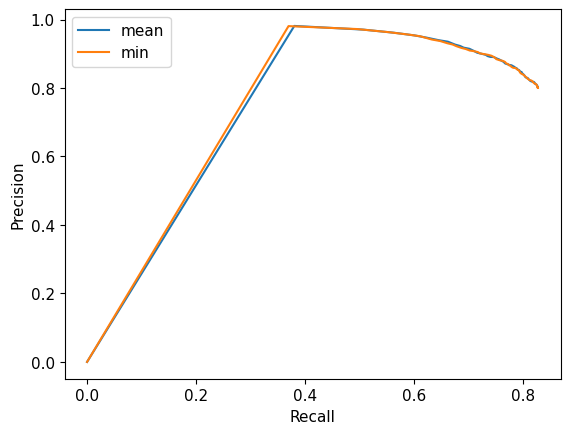

{'mean': {'threshold': 0.68, 'f1': 0.8213705748619682, 'precision': 0.8523761375126391, 'recall': 0.7925415230335318, 'initial': 0.8133764832793959}, 'min': {'threshold': 0.62, 'f1': 0.8207210133160117, 'precision': 0.8517020559487698, 'recall': 0.7919147602632404, 'initial': 0.8133764832793959}}


In [34]:
if '6.5' in BONUS_TASKS:
    thresholds = np.linspace(0, 1, 101)
    span_scores = {'mean': [], 'min': []}
    gold_count = 0
    for g, p, probs in zip(val_gold, val_pred, val_probs):
        truth = set(bio_to_spans(g))
        gold_count += len(truth)
        for start, end, kind in bio_to_spans(p):
            correct = (start, end, kind) in truth
            values = probs[start:end]
            span_scores['mean'].append((float(np.mean(values)), correct))
            span_scores['min'].append((min(values), correct))

    best_thresholds = {}
    for name, items in span_scores.items():
        values = np.array([score for score, _ in items])
        hits = np.array([ok for _, ok in items], dtype=bool)
        curve = []
        for threshold in thresholds:
            keep = values >= threshold
            tp = (hits & keep).sum()
            precision = tp / keep.sum() if keep.any() else 0.0
            recall = tp / max(1, gold_count)
            f1 = 2 * tp / max(1, gold_count + keep.sum())
            curve.append((float(precision), float(recall), float(f1)))
        assert abs(curve[0][2] - validation['f1_micro']) < 1e-8
        best = int(np.argmax([point[2] for point in curve]))
        best_thresholds[name] = dict(threshold=float(thresholds[best]), f1=curve[best][2],
                                     precision=curve[best][0], recall=curve[best][1], initial=curve[0][2])
        plt.plot([r for _, r, _ in curve], [p for p, _, _ in curve], label=name)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.legend()
    plt.show()
    print(best_thresholds)

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** На validation лучшим для средней вероятности оказался порог 0.68. F1 вырос с 0.8134 до 0.8214, примерно на 0.0080. Precision вырос с 0.8002 до 0.8524, а recall снизился с 0.8270 до 0.7925. Для минимальной вероятности лучший порог 0.62 дал F1 0.8207. Минимум определяется самым неуверенным словом спана, тогда как при усреднении его могут компенсировать остальные слова. Фильтр лишь удаляет уже предсказанные спаны и не может вернуть пропущенную сущность, поэтому повысить recall ему нечем. Порог выбран на validation, а метрики test в разделе 4.2 приведены без этого подбора.